# The IFRS 9 validation battery across six reporting dates

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- list the tests of the IFRS 9 battery, what each one asks and which supervisory expectation it comes from;
- read the lifetime PD back-test by origination cohort and by decile, and say what the engine's light means and what it does not;
- read the SICR effectiveness, the threshold stability, the stage migration and the ECL back-test, recompute the ones whose inputs the artifact keeps, and name the ones it does not;
- say what a validator concludes when a test is not evaluable, and why that is not a pass;
- compare the battery across a crisis, a recovery, a calm period and the pandemic shock on one portfolio.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the six reporting dates of case C06 (SBA 7(a) loans, U.S. Government Works, licence class `mirror-allowed`): 2006-12-31 (before the crisis), 2008-12-31 and 2010-12-31 (the crisis and the recovery), 2019-12-31 (a calm year), 2020-06-30 (the pandemic shock) and 2023-06-30. Each file `data/derived/C06/rd-<date>.json` holds the battery's rows in `tests` and the inputs the pipeline kept in `outputs`: the lifetime back-test by origination cohort (`lifetime_backtest`), the calibration by decile (`decile_calibration`), the stage summary and the weighted and single-scenario ECL.

A `tests` row is the engine's `TestResult` as the pipeline committed it: the test identifier, the model (the rung of notebook 07: `L0-km`, `L1-dth` or `L2-cox`), the segment (an origination cohort for the lifetime test), the metric or p-value, the light, and the `extras`. Each test is a Contraste **internal gate**, not a regulatory threshold, and every row records the parameters it used in `policy_version`.

All six artifacts were baked by an older engine than the one installed. The notebook prints both versions before comparing anything, and it recomputes only the tests whose inputs are in the file.

In [2]:
# Load the six reporting dates and print what each holds, with the engine version that baked it
from riskvalidation.validation import ifrs9

LANG = "en"
ROOT = Path("../../..").resolve()
DATES = ("2006-12", "2008-12", "2010-12", "2019-12", "2020-06", "2023-06")
cases = {d: json.loads((ROOT / "data" / "derived" / "C06" / f"rd-{d}.json").read_text(encoding="utf-8")) for d in DATES}

for d, c in cases.items():
    ids = sorted({t["test_id"] for t in c["tests"]})
    print(d, "| baked by engine:", c["provenance"]["riskvalidation_version"], "| test rows:", len(c["tests"]), "| distinct tests:", len(ids))
print("installed engine:", md.version("riskvalidation"))
print("the tests:", [i.split(".")[1] for i in sorted({t["test_id"] for t in cases["2008-12"]["tests"]})])
print("models in the lifetime test:", sorted({t["model_id"] for t in cases["2008-12"]["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest"}))
print("parameters recorded by a row:", cases["2008-12"]["tests"][0]["policy_version"])

2006-12 | baked by engine: 0.5.0 | test rows: 29 | distinct tests: 9
2008-12 | baked by engine: 0.5.0 | test rows: 29 | distinct tests: 9
2010-12 | baked by engine: 0.5.0 | test rows: 29 | distinct tests: 9
2019-12 | baked by engine: 0.5.0 | test rows: 29 | distinct tests: 9
2020-06 | baked by engine: 0.5.0 | test rows: 29 | distinct tests: 9
2023-06 | baked by engine: 0.5.0 | test rows: 29 | distinct tests: 9
installed engine: 0.9.0
the tests: ['ecl_backtest', 'lifetime_pd_backtest', 'nonlinearity', 'overlay_diagnostics', 'reconciliation_identities', 'scenario_sensitivity', 'sicr_effectiveness', 'sicr_threshold_stability', 'stage_migration_backtest']
models in the lifetime test: ['L0-km', 'L1-dth', 'L2-cox']
parameters recorded by a row: contraste-ifrs9-battery-1.0.0; gap_amber=0.25; gap_red=0.5; alpha_amber=0.05; alpha_red=0.01; rho=0.12; estimator=kaplan-meier


## Method

The battery follows the validation expectations the research distilled from the supervisors (EBA/Rep/2023/36 paragraphs 94 to 118; EBA/Rep/2021/35; BCBS d350 paragraphs 36 and 50 and 51; IFRS 9 B5.5.52). Each test below is one engine function that returns one `TestResult`.

| Test | What it asks | Source |
|---|---|---|
| `lifetime_pd_backtest` | does the observed cumulative default rate stay near the predicted cumulative PD at every horizon | EBA/Rep/2023/36, paragraphs 114 to 118 |
| `sicr_effectiveness` | does the Stage 2 flag select the accounts that default | EBA/Rep/2023/36, paragraphs 94 to 99; d350 A38 |
| `sicr_threshold_stability` | does the threshold loosen when conditions worsen | EBA/Rep/2023/36, paragraphs 29 to 33 |
| `stage_migration_backtest` | are the observed stage transitions drawn from the predicted matrix | EBA/Rep/2023/36, paragraph 97 |
| `ecl_backtest` | do the discounted realised losses equal the ECL, like for like and without overlays | IFRS 9 B5.5.52; EBA/Rep/2023/36, paragraphs 100 to 104 |
| `scenario_sensitivity`, `nonlinearity` | notebook 03 | d350 paragraph 36(a) |
| `overlay_diagnostics`, `reconciliation_identities` | notebook 04 | d350 paragraphs 50 and 51; IFRS 7 35H and 35I |

Four statistics carry the notebook. The ECL back-test ratio is $R_H = \sum \mathrm{realised}/\sum \mathrm{ECL}$, green when it lies in $[0.8, 1.25]$, amber in $[0.5, 2.0]$ outside that and red beyond (the engine's defaults). The SICR effectiveness metric is the ratio of the default rates $DR_{S2}/DR_{S1}$, green from 2, amber from 1, red below. The lifetime back-test metric is the largest $|\mathrm{observed} - \mathrm{predicted}|$ over the horizons, and its light, when the asset correlation $\rho$ is given, is read against the Vasicek band of the default count among the obligors at risk (Vasicek 2002; the engine's band is central at the amber and red levels $\alpha$). The stage migration statistic is the Pearson chi-square over the rows with observations (Anderson and Goodman, 1957, equation 3.1):

$$\chi^2 = \sum_{i}\sum_{j \mid p_{ij}>0} \frac{(O_{ij} - n_i\,p_{ij})^2}{n_i\,p_{ij}}, \qquad \mathrm{df} = \sum_i (\#\{j : p_{ij} > 0\} - 1)$$

An observation in a cell predicted at zero is impossible under the null: the statistic is infinite, the p-value 0 and the light red.

A test that cannot be evaluated returns the light `not_evaluated` with its reason and an undefined statistic, never a number made up. A validator reads it as the absence of a result.

### Step 1: the battery on six dates

The first view is the whole battery. For each date, the cell takes the row of each test at portfolio level (for the lifetime test, the `all` cohort of the `L1-dth` rung, the rung the pipeline uses for the ECL) and prints its light. This is the table a validation report would open with.

In [3]:
# The light of each test at portfolio level on each date
def portfolio_row(case, test_id):
    rows = [t for t in case["tests"] if t["test_id"] == test_id and t["segment"] in (None, "all") and t["model_id"] == "L1-dth"]
    return rows[0]


TEST_IDS = ["lifetime_pd_backtest", "sicr_effectiveness", "sicr_threshold_stability", "stage_migration_backtest", "ecl_backtest",
            "scenario_sensitivity", "nonlinearity", "overlay_diagnostics", "reconciliation_identities"]
lights = {tid: {d: portfolio_row(cases[d], "ifrs9." + tid)["light"] for d in DATES} for tid in TEST_IDS}
print(f"{'':28s}", *[f"{d:>14s}" for d in DATES])
for tid in TEST_IDS:
    print(f"{tid:28s}", *[f"{lights[tid][d]:>14s}" for d in DATES])
for light in ("green", "amber", "red", "not_evaluated"):
    print(light, ":", sum(1 for tid in TEST_IDS for d in DATES if lights[tid][d] == light), "of", len(TEST_IDS) * len(DATES))

                                    2006-12        2008-12        2010-12        2019-12        2020-06        2023-06
lifetime_pd_backtest                  green          green          amber          green            red          green
sicr_effectiveness                      red          amber          green  not_evaluated          amber  not_evaluated
sicr_threshold_stability              green          green          green          green            red          green
stage_migration_backtest                red            red            red            red            red            red
ecl_backtest                          amber          green            red          amber            red          amber
scenario_sensitivity                  green          green          amber          green          green          green
nonlinearity                          green          green          green          green          green          green
overlay_diagnostics                   green     

### Step 2: the lifetime PD back-test

The lifetime test compares the cumulative PD the model predicts for an origination cohort at 6, 12, ..., 36 months with the observed cumulative default rate (a Kaplan-Meier estimate). The metric is the largest absolute gap. The committed light uses the asset correlation $\rho = 0.12$ and a two-sided Vasicek band for the default count of the obligors at risk. The cell shows the 2008 horizons of the `all` cohort, with the committed band (amber level), and recomputes the **metric** with the engine from the predicted and observed values the artifact keeps. It cannot recompute the band-based light because the number of obligors at risk at each horizon is not in the file: the call without $\rho$ uses the relative-gap rule instead, which is a different light by design.

In [4]:
# Show the horizons of the all cohort with the committed band and recompute the metric with the engine
c08 = cases["2008-12"]
rows = [r for r in c08["outputs"]["lifetime_backtest"]["rows"] if r["origination_cohort"] == "all"]
committed = [t for t in c08["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest" and t["model_id"] == "L1-dth" and t["segment"] == "all"][0]
months = np.array([r["months"] for r in rows])
pred = np.array([r["predicted_cumulative_pd"] for r in rows])
obs = np.array([r["observed_cumulative_pd"] for r in rows])
low, high = np.array(committed["extras"]["band_low"]), np.array(committed["extras"]["band_high"])
for m_, p_, o_, lo, hi in zip(months, pred, obs, low, high):
    print("month", int(m_), "| predicted:", round(float(p_), 4), "| observed:", round(float(o_), 4), "| band:", round(float(lo), 4), "-", round(float(hi), 4), "| inside:", bool(lo <= o_ <= hi))

n_at_risk = np.full(months.size, committed["n"], dtype=float)
n_events = np.full(months.size, committed["n_events"], dtype=float)
recomputed = ifrs9.lifetime_pd_backtest(months, pred, obs, n_at_risk, n_events, model_id="L1-dth", segment="all")
print("largest gap, recomputed and committed:", round(recomputed.metric, 6), round(committed["metric"], 6))
print("light without rho (relative gap), recomputed:", recomputed.light.value, "| largest relative gap:", round(max(recomputed.extras["relative_gap"]), 4), "| light committed (with rho):", committed["light"])
print("baked by engine", c08["provenance"]["riskvalidation_version"], "| read with engine", md.version("riskvalidation"))

month 6 | predicted: 0.0143 | observed: 0.0168 | band: 0.0011 - 0.051 | inside: True
month 12 | predicted: 0.0298 | observed: 0.0324 | band: 0.0033 - 0.0948 | inside: True
month 18 | predicted: 0.0465 | observed: 0.0616 | band: 0.0063 - 0.1367 | inside: True
month 24 | predicted: 0.0637 | observed: 0.0804 | band: 0.0099 - 0.176 | inside: True
month 30 | predicted: 0.0803 | observed: 0.0959 | band: 0.014 - 0.2114 | inside: True
month 36 | predicted: 0.0959 | observed: 0.1083 | band: 0.0182 - 0.2428 | inside: True
largest gap, recomputed and committed: 0.01669 0.01669
light without rho (relative gap), recomputed: amber | largest relative gap: 0.3228 | light committed (with rho): green
baked by engine 0.5.0 | read with engine 0.9.0


### Step 3: by origination cohort and by decile

The same test run on each origination cohort asks whether the model is calibrated for the loans of every year, not only on average. The cell prints, for the three rungs, the metric and the light of every cohort at 2008, and the 36-month predicted and observed values of the `L1-dth` rung. Then it prints the calibration by decile of predicted risk at 12 months: the loans are sorted by their predicted PD into ten equal groups and the predicted PD of the group is set beside its observed rate.

In [5]:
# The metric and light by cohort and rung, and the calibration by decile at 12 months
cohorts = ["older", "2004", "2005", "2006", "2007", "2008", "all"]
by = {(t["model_id"], t["segment"]): t for t in c08["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest"}
print(f"{'':8s}", *[f"{rung:>20s}" for rung in ("L0-km", "L1-dth", "L2-cox")])
for cohort in cohorts:
    print(f"{cohort:8s}", *[f"{by[(rung, cohort)]['metric']:10.4f} {by[(rung, cohort)]['light']:>9s}" for rung in ("L0-km", "L1-dth", "L2-cox")])
cohort_36 = {r["origination_cohort"]: r for r in c08["outputs"]["lifetime_backtest"]["rows"] if r["months"] == 36}
print("cohort 2007 at 36 months, predicted and observed:", round(cohort_36["2007"]["predicted_cumulative_pd"], 4), round(cohort_36["2007"]["observed_cumulative_pd"], 4))

deciles = [r for r in c08["outputs"]["decile_calibration"]["rows"] if r["months"] == 12]
for r in deciles:
    print("decile", f"{r['decile']:2d}", "| n:", r["n"], "| predicted:", round(r["predicted_cumulative_pd"], 4), "| observed:", round(r["observed_cumulative_pd"], 4), "| ratio:", round(r["observed_cumulative_pd"] / r["predicted_cumulative_pd"], 2))

                        L0-km               L1-dth               L2-cox
older        0.0028     green     0.0015     green     0.0096     green
2004         0.0286     green     0.0349     green     0.0177     green
2005         0.0379     green     0.0575     green     0.0330     green
2006         0.0055     green     0.0359     green     0.0031     green
2007         0.1240     amber     0.0859     green     0.1163     amber
2008         0.0847     green     0.0445     green     0.0817     amber
all          0.0427     green     0.0167     green     0.0427     green
cohort 2007 at 36 months, predicted and observed: 0.1267 0.2006
decile  1 | n: 22760 | predicted: 0.0038 | observed: 0.0037 | ratio: 0.97
decile  2 | n: 22760 | predicted: 0.0082 | observed: 0.0126 | ratio: 1.53
decile  3 | n: 22760 | predicted: 0.0129 | observed: 0.0246 | ratio: 1.91
decile  4 | n: 22760 | predicted: 0.0182 | observed: 0.0371 | ratio: 2.04
decile  5 | n: 22760 | predicted: 0.0235 | observed: 0.0504 | ra

### Step 4: does Stage 2 select the defaulters? (SICR effectiveness)

If the staging works, accounts in Stage 2 at the reporting date should default more often in the following year than accounts in Stage 1. The metric is the ratio of the two default rates. The cell prints it for each date with the counts behind it, the area under the ROC curve of the stage as a score and the share of the defaulters that came directly from Stage 1, and checks the ratio with a division of the committed counts (a check of the definition, since the test's inputs are per account and are not in the file). A date with no Stage 2 account has no ratio.

In [6]:
# The SICR effectiveness of each date, with the counts, and the ratio checked by a division
for d in DATES:
    row = portfolio_row(cases[d], "ifrs9.sicr_effectiveness")
    x = row["extras"]
    if row["light"] == "not_evaluated":
        print(d, "|", row["light"], "| accounts:", row["n"], "| Stage 2 accounts:", sum(r["accounts"] for r in cases[d]["outputs"]["stage_summary"]["rows"] if r["stage"] == "stage2"))
        continue
    check = (x["defaults_stage2"] / x["n_stage2"]) / (x["defaults_stage1"] / x["n_stage1"])
    print(d, "|", row["light"], "| DR2/DR1:", round(row["metric"], 4), "| by division:", round(check, 4), "| DR1:", round(x["default_rate_stage1"], 4), "| DR2:", round(x["default_rate_stage2"], 4), "| AUC:", round(x["roc_auc"], 4), "| direct from Stage 1:", round(x["share_stage3_direct_from_stage1"], 3))

2006-12 | red | DR2/DR1: 0.9662 | by division: 0.9662 | DR1: 0.0164 | DR2: 0.0159 | AUC: 0.4999 | direct from Stage 1: 0.996
2008-12 | amber | DR2/DR1: 2.2525 | by division: 2.2525 | DR1: 0.035 | DR2: 0.0787 | AUC: 0.5256 | direct from Stage 1: 0.907
2010-12 | green | DR2/DR1: 2.4376 | by division: 2.4376 | DR1: 0.013 | DR2: 0.0318 | AUC: 0.5783 | direct from Stage 1: 0.153
2019-12 | not_evaluated | accounts: 271801 | Stage 2 accounts: 0
2020-06 | amber | DR2/DR1: 1.9951 | by division: 1.9951 | DR1: 0.0027 | DR2: 0.0054 | AUC: 0.5085 | direct from Stage 1: 0.018
2023-06 | not_evaluated | accounts: 251636 | Stage 2 accounts: 0


### Step 5: the threshold must not loosen when conditions worsen

`sicr_threshold_stability` counts the reporting periods in which the implied SICR multiplier rises while a condition index rises too: green with none, amber with at least one, red when the count is at least half of the periods. The committed rows compare two periods each. To show all three lights, the cell also runs the engine function on three **constructed** series of six periods, labelled as such.

In [7]:
# The committed stability rows, and the engine's three lights on constructed series
for d in DATES:
    row = portfolio_row(cases[d], "ifrs9.sicr_threshold_stability")
    print(d, "|", row["light"], "| periods that loosen:", row["extras"]["loosening_periods"], "| of", row["extras"]["periods"])
condition = np.array([1.0, 2.0, 3.0, 2.5, 4.0, 5.0])
series = {
    "multiplier falls as conditions worsen": np.array([3.0, 2.8, 2.6, 2.6, 2.4, 2.2]),
    "two periods loosen": np.array([2.0, 2.0, 2.5, 2.5, 3.0, 3.0]),
    "the multiplier rises with every worsening": np.array([2.0, 2.2, 2.5, 2.5, 2.8, 3.1]),
}
for label, multiplier in series.items():
    r = ifrs9.sicr_threshold_stability(multiplier, condition)
    print(f"{label:62s}", r.light.value, "| count:", int(r.metric), "| periods:", r.extras["loosening_periods"])

2006-12 | green | periods that loosen: [] | of 2
2008-12 | green | periods that loosen: [] | of 2
2010-12 | green | periods that loosen: [] | of 2
2019-12 | green | periods that loosen: [] | of 2
2020-06 | red | periods that loosen: [1] | of 2
2023-06 | green | periods that loosen: [] | of 2
multiplier falls as conditions worsen                          green | count: 0 | periods: []
two periods loosen                                             amber | count: 2 | periods: [2, 4]
the multiplier rises with every worsening                      red | count: 4 | periods: [1, 2, 4, 5]


### Step 6: the stage migration back-test

`stage_migration_backtest` compares a predicted 3 by 3 matrix of one-year stage transitions with the observed counts through the chi-square above. In the committed rows the light is red on all six dates and the p-value is 0. The cell reads why from the `extras` (an observation in a cell predicted at zero, or a statistic so large that the p-value is 0) and then runs the engine function on two **constructed** cases to show the two ways a row turns red: a matrix with a zero cell and an observation in it, and a matrix whose counts differ a little from its prediction.

In [8]:
# Why the committed rows are red, and the two ways a constructed case turns red or stays green
for d in DATES:
    row = portfolio_row(cases[d], "ifrs9.stage_migration_backtest")
    x = row["extras"]
    print(d, "|", row["light"], "| p:", row["p_value"], "| accounts:", row["n"], "| df:", x["degrees_of_freedom"], "| rows skipped:", x["rows_skipped"], "| impossible cell observed:", x["impossible_cell_observed"])

predicted = np.array([[0.90, 0.08, 0.02], [0.20, 0.70, 0.10], [0.00, 0.00, 1.00]])
close = np.array([[905, 75, 20], [21, 68, 11], [0, 0, 10]])
impossible = np.array([[900, 80, 20], [20, 70, 10], [1, 0, 9]])
shifted = np.array([[800, 150, 50], [40, 50, 10], [0, 0, 10]])
for label, counts in (("counts near the prediction", close), ("a count in a cell predicted at zero", impossible), ("counts that moved a lot", shifted)):
    r = ifrs9.stage_migration_backtest(predicted, counts, model_id="lesson")
    print(f"{label:58s}", r.light.value, "| statistic:", round(r.statistic, 3) if math.isfinite(r.statistic) else "inf", "| p:", round(r.p_value, 4), "| df:", r.extras["degrees_of_freedom"])

2006-12 | red | p: 0.0 | accounts: 225212 | df: 1 | rows skipped: 2 | impossible cell observed: True
2008-12 | red | p: 0.0 | accounts: 273225 | df: 1 | rows skipped: 2 | impossible cell observed: True
2010-12 | red | p: 0.0 | accounts: 248757 | df: 4 | rows skipped: 1 | impossible cell observed: False
2019-12 | red | p: 1.24884073e-60 | accounts: 229819 | df: 1 | rows skipped: 2 | impossible cell observed: False
2020-06 | red | p: 0.0 | accounts: 232633 | df: 1 | rows skipped: 2 | impossible cell observed: True
2023-06 | red | p: 9.64639127e-33 | accounts: 205785 | df: 1 | rows skipped: 2 | impossible cell observed: False
counts near the prediction                                 green | statistic: 0.547 | p: 0.9687 | df: 4
a count in a cell predicted at zero                        red | statistic: inf | p: 0.0 | df: 4
counts that moved a lot                                    red | statistic: 143.075 | p: 0.0 | df: 4


### Step 7: the ECL back-test, recomputed

The ECL back-test needs two numbers: the sum of the discounted losses realised in the 12 months after the reporting date and the sum of the 12-month ECL of the same accounts, overlays excluded. The ratio $R_H$ depends only on the two sums, and the artifact keeps both. The cell calls `ecl_backtest` with the two sums as one-element arrays (the light and the ratio are those of the account-level call, only the count $n$ differs) and compares with the committed rows.

In [9]:
# Recompute R_H and the light from the two committed sums of each date
r_values = {}
for d in DATES:
    row = portfolio_row(cases[d], "ifrs9.ecl_backtest")
    x = row["extras"]
    r = ifrs9.ecl_backtest(np.array([x["sum_realised"]]), np.array([x["sum_ecl"]]), x["horizon_months"], model_id="L1-dth")
    r_values[d] = r.metric
    print(d, "| realised, USD millions:", round(x["sum_realised"] / 1e6, 1), "| ECL:", round(x["sum_ecl"] / 1e6, 1), "| R_H:", round(r.metric, 4), "| committed:", round(row["metric"], 4), "|", r.light.value, "| same light:", r.light.value == row["light"])

2006-12 | realised, USD millions: 342.8 | ECL: 457.3 | R_H: 0.7496 | committed: 0.7496 | amber | same light: True
2008-12 | realised, USD millions: 879.1 | ECL: 840.5 | R_H: 1.046 | committed: 1.046 | green | same light: True
2010-12 | realised, USD millions: 819.5 | ECL: 1752.0 | R_H: 0.4678 | committed: 0.4678 | red | same light: True
2019-12 | realised, USD millions: 325.7 | ECL: 579.6 | R_H: 0.5619 | committed: 0.5619 | amber | same light: True
2020-06 | realised, USD millions: 313.1 | ECL: 4393.5 | R_H: 0.0713 | committed: 0.0713 | red | same light: True
2023-06 | realised, USD millions: 496.0 | ECL: 777.6 | R_H: 0.6378 | committed: 0.6378 | amber | same light: True


### Step 8: scenario sensitivity, recomputed

`scenario_sensitivity` needs the ECL at 100% of each scenario, the weights and the ECL at the mean path. The artifact keeps all three, so the cell recomputes the index $\mathrm{NL}$ and the light for every date with the engine, with the weights read from `outputs.scenarios`.

In [10]:
# Recompute the non-linearity index and its light for every date from the committed scenario ECLs
for d in DATES:
    row = portfolio_row(cases[d], "ifrs9.scenario_sensitivity")
    x = row["extras"]
    weights = np.array([s["weight"] for s in cases[d]["outputs"]["scenarios"]])
    r = ifrs9.scenario_sensitivity(np.array(x["single_scenario_ecl"]), weights, x["ecl_at_mean_path"], model_id="L1-dth")
    ordered = bool(np.all(np.diff(x["single_scenario_ecl"]) >= 0))
    print(d, "| NL:", round(r.metric, 5), "| committed:", round(row["metric"], 5), "|", r.light.value, "| same light:", r.light.value == row["light"], "| ECL rises with the severity of the scenario:", ordered)

2006-12 | NL: 0.00211 | committed: 0.00211 | green | same light: True | ECL rises with the severity of the scenario: False
2008-12 | NL: 0.02121 | committed: 0.02121 | green | same light: True | ECL rises with the severity of the scenario: False
2010-12 | NL: -0.00071 | committed: -0.00071 | amber | same light: True | ECL rises with the severity of the scenario: True
2019-12 | NL: 0.0232 | committed: 0.0232 | green | same light: True | ECL rises with the severity of the scenario: True
2020-06 | NL: 0.01279 | committed: 0.01279 | green | same light: True | ECL rises with the severity of the scenario: False
2023-06 | NL: 0.00622 | committed: 0.00622 | green | same light: True | ECL rises with the severity of the scenario: True


### Step 9: what a validator concludes when a test is not evaluable

On 2019-12-31 and 2023-06-30 there is no Stage 2 account, so the default rate of Stage 2 does not exist and `sicr_effectiveness` returns `not_evaluated` with an undefined metric. The cell reproduces the situation on a **constructed** sample with only Stage 1 accounts, and with a Stage 2 that has no defaults in Stage 1, and prints the light and whether the metric is undefined. The conclusion is not that the staging is good: it is that this test says nothing at this date, and the validator must say so in the report.

In [11]:
# Run the effectiveness test on constructed samples where it cannot be evaluated
rng = np.random.default_rng(7)
n = 200
only_stage1 = np.ones(n)
defaulted = rng.random(n) < 0.05
months_in_s2 = np.where(defaulted, 0.0, np.nan)
direct = defaulted.copy()
backstop = np.zeros(n, dtype=bool)
no_stage2 = ifrs9.sicr_effectiveness(only_stage1, defaulted, 12, months_in_s2, direct, backstop, model_id="lesson")
print("no Stage 2 account:", no_stage2.light.value, "| metric is undefined:", math.isnan(no_stage2.metric))

stage = np.where(np.arange(n) < 20, 2.0, 1.0)
never = np.zeros(n, dtype=bool)
no_defaults_in_stage1 = ifrs9.sicr_effectiveness(stage, np.arange(n) < 3, 12, np.where(np.arange(n) < 3, 2.0, np.nan), np.zeros(n, dtype=bool), backstop, model_id="lesson")
print("no default in Stage 1:", no_defaults_in_stage1.light.value, "| metric is undefined:", math.isnan(no_defaults_in_stage1.metric))
print("committed rows not evaluated:", [d for d in DATES if portfolio_row(cases[d], "ifrs9.sicr_effectiveness")["light"] == "not_evaluated"])

no Stage 2 account: not_evaluated | metric is undefined: True
no default in Stage 1: not_evaluated | metric is undefined: True
committed rows not evaluated: ['2019-12', '2023-06']


### Step 10: the battery, drawn

The left panel is the grid of step 1 in colour: a row per test, a column per date, green, amber, red or grey for a test not evaluated. The right panel is the ECL back-test ratio $R_H$ by date on a logarithmic axis, with the engine's default green band from 0.8 to 1.25 and amber band from 0.5 to 2.0 (the defaults the function documents).

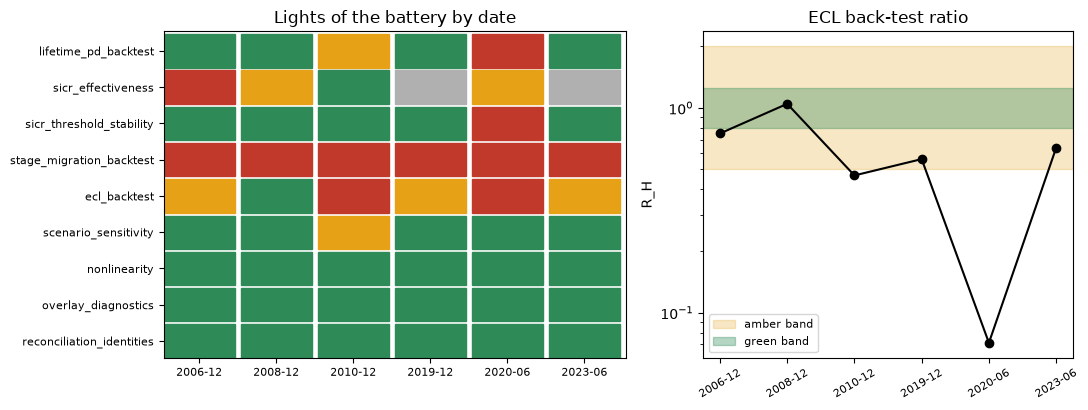

In [12]:
# Draw the grid of lights and the ECL back-test ratio by date
palette = {"green": "#2e8b57", "amber": "#e6a117", "red": "#c0392b", "not_evaluated": "#b0b0b0"}
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
for i, tid in enumerate(TEST_IDS):
    for j, d in enumerate(DATES):
        left.add_patch(plt.Rectangle((j, len(TEST_IDS) - 1 - i), 0.92, 0.92, color=palette[lights[tid][d]]))
left.set_xlim(0, len(DATES))
left.set_ylim(0, len(TEST_IDS))
left.set_xticks(np.arange(len(DATES)) + 0.46)
left.set_xticklabels(DATES, fontsize=8)
left.set_yticks(np.arange(len(TEST_IDS)) + 0.46)
left.set_yticklabels(TEST_IDS[::-1], fontsize=8)
left.set_title("Lights of the battery by date")

right.axhspan(0.5, 2.0, color="#e6a117", alpha=0.25, label="amber band")
right.axhspan(0.8, 1.25, color="#2e8b57", alpha=0.35, label="green band")
right.plot(range(len(DATES)), [r_values[d] for d in DATES], marker="o", color="black")
right.set_yscale("log")
right.set_xticks(range(len(DATES)))
right.set_xticklabels(DATES, fontsize=8, rotation=30)
right.set_ylabel("R_H")
right.set_title("ECL back-test ratio")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **The battery in one table.** Of the 54 cells (nine tests, six dates) 34 are green, 7 amber, 11 red and 2 not evaluated. Three tests are green on every date: the non-linearity, the overlay diagnostics and the reconciliation identities, which check the engine's arithmetic and the tables (notebooks 03 and 04). Another is red on every date: the stage migration. The informative columns are the others.
- **The lifetime PD test depends on its rule.** In 2008 the largest gap on the `all` cohort is 0.01669 for the `L1-dth` rung, equal to the committed metric, and the observed cumulative PD lies inside the committed band at the six horizons, so the committed light is green. The call without $\rho$ uses the relative-gap rule, whose largest relative gap is 0.3228, above the 0.25 cut-off, and gives amber. Neither is wrong: the band says the gap is compatible with the correlation of defaults the policy assumes ($\rho = 0.12$), the relative gap says the 36-month prediction is a third off. A validator reports the rule with the light.
- **The pooled result hides the cohorts.** The 2007 cohort is amber for `L0-km` (0.1240) and `L2-cox` (0.1163) and green for `L1-dth` (0.0859); at 36 months it was predicted at 0.1267 and observed at 0.2006. The 2008 cohort is amber for `L2-cox`. On the pooled `all` cohort the three rungs are green with metrics of 0.0427, 0.0167 and 0.0427.
- **The decile calibration is not monotone.** At 12 months the observed-to-predicted ratio is 0.97 in decile 1, 2.14 in decile 5, 0.50 in decile 9 and 0.77 in decile 10: the loans the model calls riskiest default less than predicted and the middle ones more. The rank order of the prediction is only loosely the order of the outcomes.
- **SICR effectiveness changes sign with the date.** The ratio of the default rate of Stage 2 to that of Stage 1 is 0.9662 in 2006 (Stage 2 defaulted slightly less than Stage 1, red, area under the ROC curve 0.4999), 2.2525 in 2008 (amber), 2.4376 in 2010 (green) and 1.9951 in 2020-06 (amber, just under the green cut-off of 2). The division of the committed counts gives the same ratios. The share of defaulters that came directly from Stage 1 is 99.6% in 2006 and 90.7% in 2008 and 15.3% in 2010: in the crisis most of the defaulters of the following year were still in Stage 1 at the reporting date.
- **The threshold stability test fires once.** Only 2020-06 is red (one of two periods loosens, which is half). On constructed series the engine gives green for none, amber for two loosening periods and red for four of six.
- **The stage migration test is red everywhere, for a reason a validator must read.** In 2006, 2008 and 2020-06 an observation falls in a cell the predicted matrix assigns zero (statistic infinite, p-value 0); in the other dates the statistic is so large that the p-value is 0 (2010-12) or 1.2e-60 and 9.6e-33 (2019-12 and 2023-06). The artifact does not say which cell is impossible; the high shares of defaults that reach Stage 3 straight from Stage 1 are consistent with it. The constructed cases show the two sides: counts near the prediction give a statistic of 0.547 and a p-value of 0.9687, and counts that moved give 143.075.
- **The ECL back-test says the allowance was above the realised loss on five of six dates.** $R_H$ is 0.7496, 1.046, 0.4678, 0.5619, 0.0713 and 0.6378, equal to the committed values and lights. Only 2008 is green. In 2020-06 the realised discounted loss is 313.1 millions of USD against an ECL of 4,393.5 millions, a ratio of 0.0713, and the light is red.
- **The scenario sensitivity recomputes exactly,** and shows that the ECL rises with the severity of the scenario on 2010-12, 2019-12 and 2023-06 and does not on 2006-12, 2008-12 and 2020-06, the dates carrying the finding `F-SCENARIO-ORDER`. In 2010-12 the index is negative ($-0.00071$), amber, because a weighted ECL below the ECL at the mean path is unexpected for a convex loss.
- **A test that cannot be evaluated is not a pass.** On 2019-12 and 2023-06 there is no Stage 2 account, so the effectiveness test returns `not_evaluated` with an undefined metric. The constructed samples reproduce it for no Stage 2 account and for no default in Stage 1. The report must say that the staging was not tested on those dates.

What this notebook does not show: the engine versions differ (the rows were baked with 0.5.0 and read here with 0.8.1), so the recomputations are of the tests whose inputs the file keeps and agree with the committed rows to the digits printed. The lights are Contraste's internal gates, and the observed outcomes are charge-offs of SBA loans, not defaults of a mortgage book.

## Summary

- The IFRS 9 battery has nine tests, each one engine function returning one `TestResult`, each an internal gate with its parameters recorded in the row.
- Recompute what the artifact's inputs allow (the ECL back-test, the scenario sensitivity, the lifetime metric, the SICR ratio by division) and read the rest as committed rows.
- A light depends on its rule: the lifetime test is green with the Vasicek band and amber with the relative gap on the same numbers, so a report states the rule.
- The pooled result hides cohorts and deciles; the effectiveness of the staging changes with the date and is not evaluable when there is no Stage 2.
- A test that cannot be evaluated is the absence of a result; the stage migration test is red on every date and the reason is in its `extras`.

**What to try next.** Open the `L0-km` and `L2-cox` rows of 2008 and compare their cohort gaps with `L1-dth`; change the constructed `predicted` matrix of step 6 so that the zero cell is small but positive. Then continue with notebook 06, which provisions one bank under three regimes.

## References

- EBA (2023), IFRS 9 implementation by EU institutions, 2023 monitoring report, EBA/Rep/2023/36, paragraphs 29 to 33 and 94 to 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- EBA (2021), IFRS 9 implementation by EU institutions, monitoring report, EBA/Rep/2021/35. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2021/1024609/IFRS9%20monitoring%20report.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm
- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), equation (3.1). https://doi.org/10.1214/aoms/1177707039
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 June 2016, sections 2.1.1, 2.7.2 and 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf